In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
match_left = cv2.imread("assignment-3-data/match_left.jpg", cv2.IMREAD_GRAYSCALE)
plt.figure()
plt.imshow(match_left, cmap='gray')
print(match_left.shape, match_left.dtype)

match_right = cv2.imread("assignment-3-data/match_right.jpg", cv2.IMREAD_GRAYSCALE)
plt.figure()
plt.imshow(match_right, cmap='gray')
print(match_right.shape, match_right.dtype)

In [21]:
def find_best_match(patch, strip, match_type) :
    patch = patch.astype(np.float64)
    strip = strip.astype(np.float64)

    w = patch.shape[1]
    W = strip.shape[1]

    n_positions = W - w + 1
    scores = np.zeros(n_positions)

    for i in range(n_positions) :
        window = strip[:, i:i+w]

        if match_type == 0:  ## SSD
            scores[i] = np.sum((patch - window) **2)

        elif match_type == 1:  # NCC
            patch_zm = patch - np.mean(patch)
            window_zm = window - np.mean(window)
            scores[i] = np.sum(patch_zm * window_zm) / (np.sqrt(np.sum(patch_zm**2)) * np.sqrt(np.sum(window_zm**2)))

    if match_type == 0:  # SSD
        best_match_position = np.argmin(scores)
    elif match_type == 1:  # NCC
        best_match_position = np.argmax(scores)

    return best_match_position, scores


In [22]:
def print_click(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        print(x, y)

cv2.namedWindow("left")
cv2.setMouseCallback("left", print_click)
cv2.imshow("left", match_left)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [23]:
x = 302
y = 137
w = 21
h = 21

patch = match_left[y - h // 2 : y + h // 2 + 1, x - w // 2 : x + w // 2 + 1]
strip = match_right[y - h // 2 : y + h // 2 + 1, :]

best_ssd, scores_ssd = find_best_match(patch, strip, 0)
print("Best SSD match position:", best_ssd)
print("SSD match scores:", scores_ssd[best_ssd])

best_ncc, scores_ncc = find_best_match(patch, strip, 1)
print("Best NCC match position:", best_ncc)
print("NCC match scores:", scores_ncc[best_ncc])


Best SSD match position: 259
SSD match scores: 55340.0
Best NCC match position: 259
NCC match scores: 0.9672567930810384


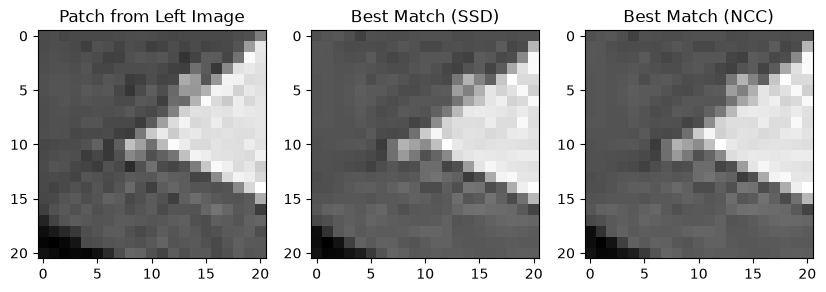

In [28]:
matched_ssd = strip[:, best_ssd : best_ssd + w]
matched_ncc = strip[:, best_ncc : best_ncc + w]

plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(patch, cmap='gray')
plt.title('Patch from Left Image')
plt.subplot(1, 3, 2)
plt.imshow(matched_ssd, cmap='gray')
plt.title('Best Match (SSD)')
plt.subplot(1, 3, 3)
plt.imshow(matched_ncc, cmap='gray')
plt.title('Best Match (NCC)')
plt.savefig("assignment-3-data/outputs_1/patches.png")
plt.show()




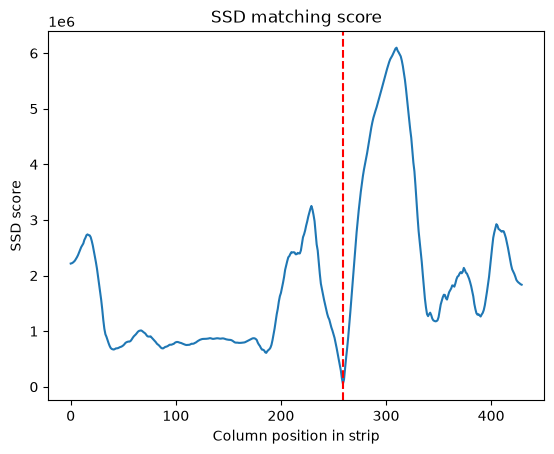

In [25]:
plt.figure()
plt.plot(scores_ssd)
plt.axvline(best_ssd, color='r', linestyle='--')
plt.xlabel("Column position in strip")
plt.ylabel("SSD score")
plt.title("SSD matching score")
plt.savefig("assignment-3-data/outputs_1/ssd_scores.png")
plt.show()


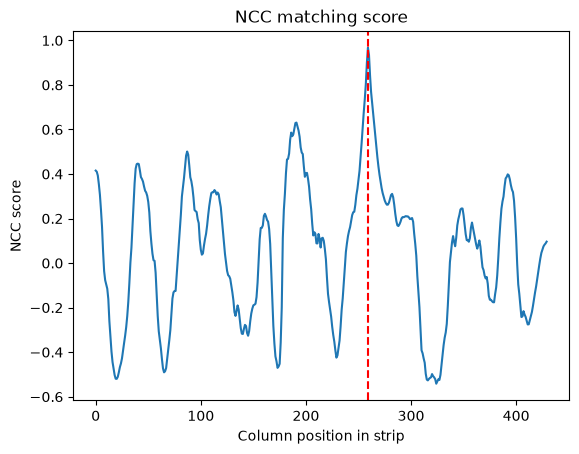

In [26]:
plt.figure()
plt.plot(scores_ncc)
plt.axvline(best_ncc, color='r', linestyle='--')
plt.xlabel("Column position in strip")
plt.ylabel("NCC score")
plt.title("NCC matching score")
plt.savefig("assignment-3-data/outputs_1/ncc_scores.png")
plt.show()



Best SSD match position: 283
SSD score at best: 2759.0
Best NCC match position: 267
NCC score at best: 0.8199045630037348


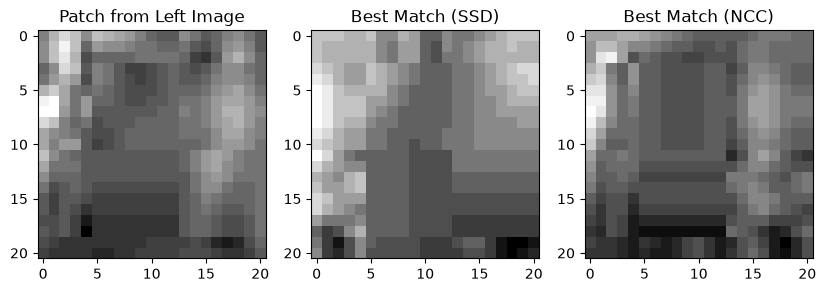

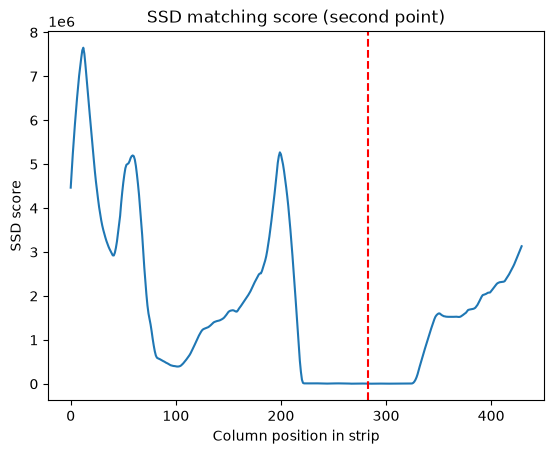

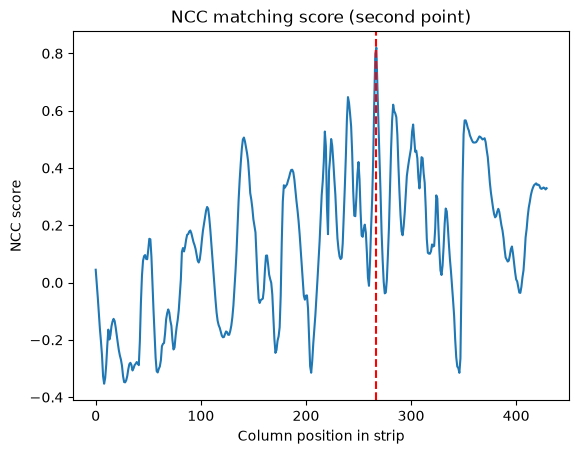

In [27]:
x2 = 309   
y2 = 215   
w2 = 21
h2 = 21

patch_2 = match_left[y2 - h2 // 2 : y2 + h2 // 2 + 1, x2 - w2 // 2 : x2 + w2 // 2 + 1]
strip_2 = match_right[y2 - h2 // 2 : y2 + h2 // 2 + 1, :]

best_ssd_2, scores_ssd_2 = find_best_match(patch_2, strip_2, 0)
best_ncc_2, scores_ncc_2 = find_best_match(patch_2, strip_2, 1)

print("Best SSD match position:", best_ssd_2)
print("SSD score at best:", scores_ssd_2[best_ssd_2])
print("Best NCC match position:", best_ncc_2)
print("NCC score at best:", scores_ncc_2[best_ncc_2])


matched_ssd_2 = strip_2[:, best_ssd_2 : best_ssd_2 + w2]
matched_ncc_2 = strip_2[:, best_ncc_2 : best_ncc_2 + w2]

cv2.imwrite("assignment-3-data/outputs_1/patch_left_2.png", patch_2)
cv2.imwrite("assignment-3-data/outputs_1/match_ssd_2.png", matched_ssd_2)
cv2.imwrite("assignment-3-data/outputs_1/match_ncc_2.png", matched_ncc_2)

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(patch_2, cmap='gray')
axes[0].set_title("Patch from Left Image")
axes[1].imshow(matched_ssd_2, cmap='gray')
axes[1].set_title("Best Match (SSD)")
axes[2].imshow(matched_ncc_2, cmap='gray')
axes[2].set_title("Best Match (NCC)")
plt.savefig("assignment-3-data/outputs_1/patches_2.png")
plt.show()


plt.figure()
plt.plot(scores_ssd_2)
plt.axvline(best_ssd_2, color='r', linestyle='--')
plt.xlabel("Column position in strip")
plt.ylabel("SSD score")
plt.title("SSD matching score (second point)")
plt.savefig("assignment-3-data/outputs_1/ssd_scores_2.png")
plt.show()


plt.figure()
plt.plot(scores_ncc_2)
plt.axvline(best_ncc_2, color='r', linestyle='--')
plt.xlabel("Column position in strip")
plt.ylabel("NCC score")
plt.title("NCC matching score (second point)")
plt.savefig("assignment-3-data/outputs_1/ncc_scores_2.png")
plt.show()